In [ ]:
from sklearn.impute import SimpleImputer, KNNImputer, IterativeImputer
from sklearn.preprocessing import StandardScaler, OrdinalEncoder
from sklearn.feature_selection import mutual_info_classif
from sklearn.experimental import enable_iterative_imputer
from sklearn.base import BaseEstimator, TransformerMixin
from imblearn.pipeline import Pipeline as ImbPipeline
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import cross_val_score
from sklearn.neighbors import LocalOutlierFactor
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np

In [2]:
df = sns.load_dataset('penguins')
df.head()

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,Male
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,Female
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,Female
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,Female


In [3]:
import joblib


joblib.dump(df, '../data/raw/penguins.csv')

['../data/raw/penguins.csv']

In [4]:
df.isnull().sum()

species               0
island                0
bill_length_mm        2
bill_depth_mm         2
flipper_length_mm     2
body_mass_g           2
sex                  11
dtype: int64

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 344 entries, 0 to 343
Data columns (total 7 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   species            344 non-null    str    
 1   island             344 non-null    str    
 2   bill_length_mm     342 non-null    float64
 3   bill_depth_mm      342 non-null    float64
 4   flipper_length_mm  342 non-null    float64
 5   body_mass_g        342 non-null    float64
 6   sex                333 non-null    str    
dtypes: float64(4), str(3)
memory usage: 18.9 KB


In [6]:
num_cols = ['bill_length_mm', 'bill_depth_mm', 'flipper_length_mm', 'body_mass_g']
cat_cols = ['island', 'sex']

In [7]:
np.random.seed(42)
cols_to_corrupt = ['bill_length_mm', 'bill_depth_mm', 'flipper_length_mm']
missing_ratio = 0.15

for col in cols_to_corrupt:
    # Создаем случайную маску для 15% строк
    mask = np.random.rand(len(df)) < missing_ratio
    df.loc[mask, col] = np.nan

In [8]:
X = df.drop('species', axis=1)
y = df['species']

# Импутация: SimpleImputer, KNN, IterativeImputer

Так как LOF не умеет работать с NaN значениями, заполним пропуски до работы с выбросами.

In [9]:
preprocessor_encode = ColumnTransformer([
    ('cat', OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1), cat_cols),
    ('num', 'passthrough', num_cols)
])

## 1.1 SimpleImputer

In [10]:
pipe_simple = Pipeline([
    ('impute_cat', SimpleImputer(strategy='most_frequent')),
    ('impute_num', SimpleImputer(strategy='median')),
])

In [11]:
pipe_simple = Pipeline([
    ('encode', preprocessor_encode), # Кодирование категорий
    ('impute', SimpleImputer(strategy='median')), # Импутация медианой/молой (для смешанных данных лучше median/most_frequent по отдельности, но здесь упрощаем)
    ('scale', StandardScaler()),
    ('model', RandomForestClassifier(random_state=42))
])

# Для SimpleImputer с разными стратегиями для cat и num используем ColumnTransformer внутри пайплайна
simple_imputer_ct = ColumnTransformer([
    ('cat_imp', SimpleImputer(strategy='most_frequent'), list(range(len(cat_cols)))), # Индексы 0,1 (после encode)
    ('num_imp', SimpleImputer(strategy='median'), list(range(len(cat_cols), len(cat_cols)+len(num_cols)))) # Индексы 2,3,4,5
])

pipe_simple_correct = Pipeline([
    ('encode', preprocessor_encode),
    ('impute', simple_imputer_ct),
    ('scale', StandardScaler()),
    ('model', RandomForestClassifier(random_state=42))
])


In [12]:
simple_ct = ColumnTransformer([
    ('cat', SimpleImputer(strategy='most_frequent'), cat_cols),
    ('num', SimpleImputer(strategy='median'), num_cols)
])
pipe_simple = Pipeline([
    ('preproc', simple_ct),
    ('scale', StandardScaler()),
    ('model', RandomForestClassifier(random_state=42))
])

## 1.2 KNN

In [13]:
pipe_knn = Pipeline([
    ('encode', preprocessor_encode),
    ('impute', KNNImputer(n_neighbors=5)),
    ('scale', StandardScaler()),
    ('model', RandomForestClassifier(random_state=42))
])

## 1.3 IterativeImputer

In [14]:
pipe_iterative = Pipeline([
    ('encode', preprocessor_encode),
    ('impute', IterativeImputer(max_iter=20, random_state=42)),
    ('scale', StandardScaler()),
    ('model', RandomForestClassifier(random_state=42))
])

## 1.4 Оценка

In [15]:
scores_simple = cross_val_score(pipe_simple_correct, X, y, cv=5, scoring='roc_auc_ovo').mean()

In [16]:
scores_knn = cross_val_score(pipe_knn, X, y, cv=5, scoring='roc_auc_ovo').mean()

In [17]:
scores_iterative = cross_val_score(pipe_iterative, X, y, cv=5, scoring='roc_auc_ovo').mean()

In [18]:
print(f"Simple Imputer:  {scores_simple:.4f}")
print(f"KNN Imputer:     {scores_knn:.4f}")
print(f"Iterative Imputer: {scores_iterative:.4f}")

Simple Imputer:  0.9965
KNN Imputer:     0.9864
Iterative Imputer: 0.9925


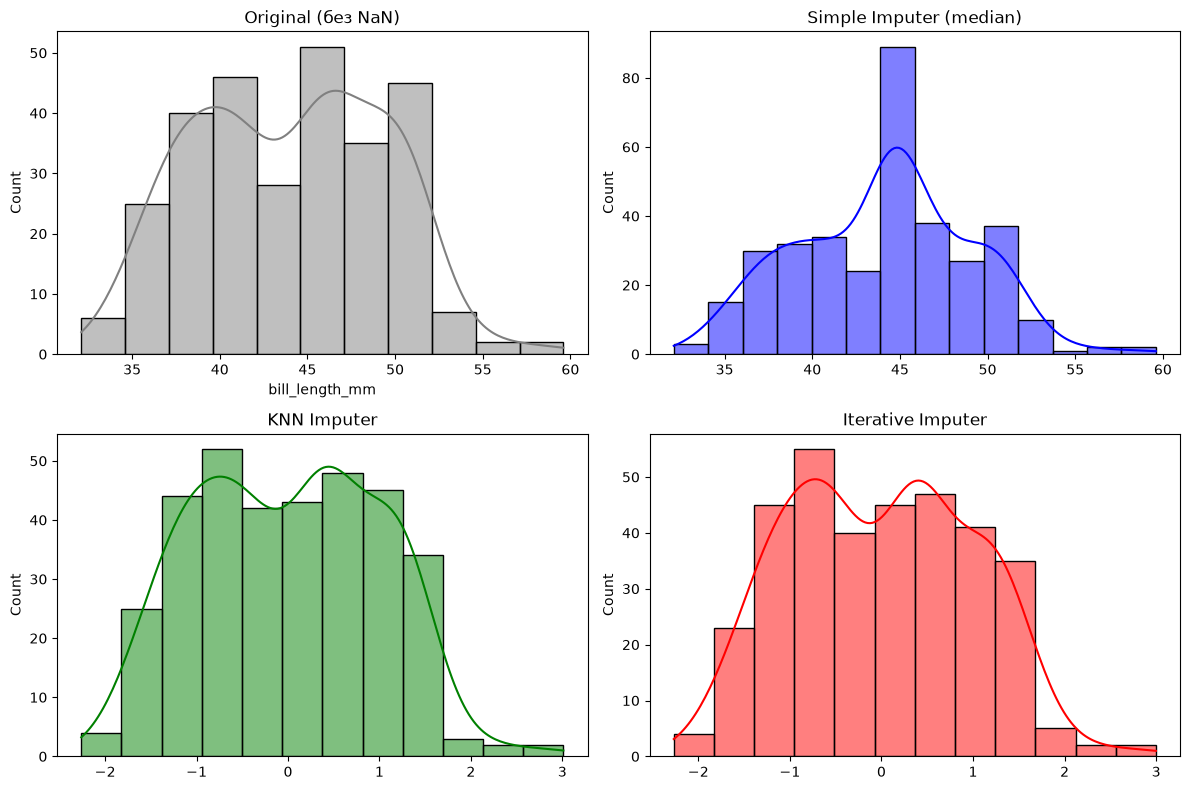

In [19]:
col_to_plot = 'bill_length_mm'

plt.figure(figsize=(12, 8))

plt.subplot(2, 2, 1)
sns.histplot(X[col_to_plot].dropna(), kde=True, color='gray')
plt.title('Original (без NaN)')

X_simple = simple_ct.fit_transform(X)
plt.subplot(2, 2, 2)
sns.histplot(X_simple[:, 2], kde=True, color='blue')
plt.title('Simple Imputer (median)')

X_knn = pipe_knn[:-1].fit_transform(X)
plt.subplot(2, 2, 3)
sns.histplot(X_knn[:, 2], kde=True, color='green')
plt.title('KNN Imputer')

X_iter = pipe_iterative[:-1].fit_transform(X)
plt.subplot(2, 2, 4)
sns.histplot(X_iter[:, 2], kde=True, color='red')
plt.title('Iterative Imputer')

plt.tight_layout()
plt.show()

# LOF

In [20]:
X_encoded = preprocessor_encode.fit_transform(X)
X_imputed = IterativeImputer(max_iter=20, random_state=42).fit_transform(X_encoded)

In [21]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_imputed)

In [22]:
print(f"Размер данных: {X_scaled.shape}")
print(f"Пропусков: {np.isnan(X_scaled).sum()}")

Размер данных: (344, 6)
Пропусков: 0


In [23]:
lof = LocalOutlierFactor(n_neighbors=20, contamination=0.05, novelty=False)
outlier_labels = lof.fit_predict(X_scaled)  # -1 = выброс, 1 = норма
outlier_scores = lof.negative_outlier_factor_ 
print(f"\nОбнаружено выбросов: {(outlier_labels == -1).sum()} из {len(outlier_labels)}")


Обнаружено выбросов: 18 из 344


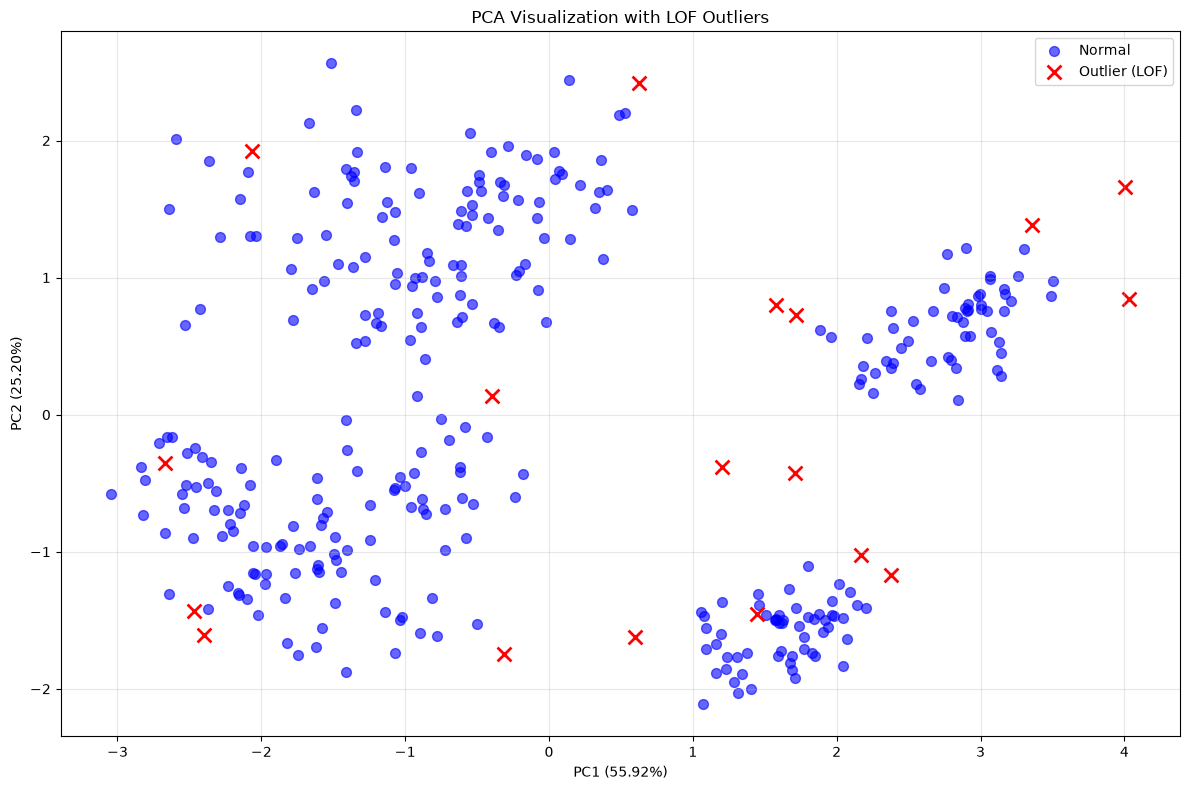

In [24]:
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_scaled)

plt.figure(figsize=(12, 8))

# Нормальные точки
normal_mask = outlier_labels == 1
plt.scatter(X_pca[normal_mask, 0], X_pca[normal_mask, 1], 
           c='blue', label='Normal', alpha=0.6, s=50)

# Выбросы
outlier_mask = outlier_labels == -1
plt.scatter(X_pca[outlier_mask, 0], X_pca[outlier_mask, 1], 
           c='red', label='Outlier (LOF)', marker='x', s=100, linewidths=2)

plt.xlabel(f'PC1 ({pca.explained_variance_ratio_[0]:.2%})')
plt.ylabel(f'PC2 ({pca.explained_variance_ratio_[1]:.2%})')
plt.title('PCA Visualization with LOF Outliers')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [25]:
preproc_for_lof = Pipeline([
    ('encode', preprocessor_encode), 
    ('impute', IterativeImputer(max_iter=20, random_state=42)),
    ('scale', StandardScaler())
])

X_processed = preproc_for_lof.fit_transform(X)

In [26]:
class OutlierRemover(BaseEstimator, TransformerMixin):
    def __init__(self, contamination=0.05, n_neighbors=20):
        self.contamination = contamination
        self.n_neighbors = n_neighbors
        self.inlier_mask_ = None

    def fit(self, X, y=None):
        # Используем novelty=False, как в Шаге 4
        lof = LocalOutlierFactor(n_neighbors=self.n_neighbors, 
                                 contamination=self.contamination, 
                                 novelty=False)
        # fit_predict дает те же результаты, что и в Шаге 4
        labels = lof.fit_predict(X)
        self.inlier_mask_ = labels == 1
        return self

    def transform(self, X, y=None):
        # Применяем маску, сохраненную при fit
        if y is not None:
            return X[self.inlier_mask_], y[self.inlier_mask_]
        return X[self.inlier_mask_]

In [27]:
outlier_remover = OutlierRemover(contamination=0.05, n_neighbors=20)

outlier_remover.fit(X_processed, y)
X_clean, y_clean = outlier_remover.transform(X_processed, y)

In [28]:
print(f"Исходный размер данных: {len(X)}")
print(f"Размер после удаления выбросов: {len(X_clean)}")
print(f"Удалено строк: {len(X) - len(X_clean)} ({(len(X) - len(X_clean))/len(X)*100:.2f}%)")


Исходный размер данных: 344
Размер после удаления выбросов: 326
Удалено строк: 18 (5.23%)


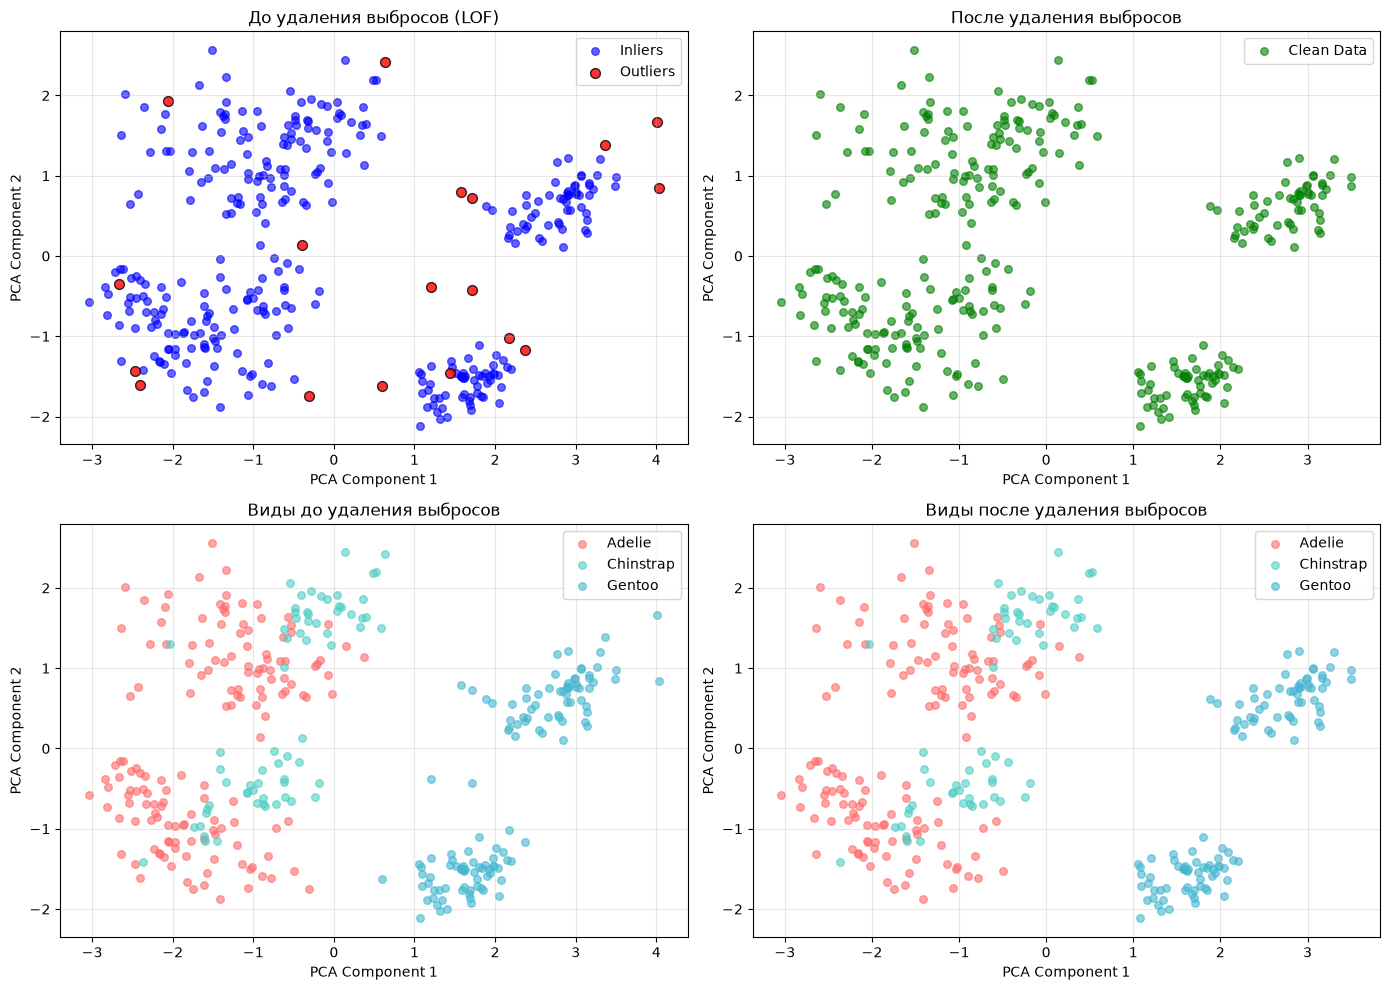


Баланс классов после удаления выбросов:
species
Adelie       147
Gentoo       113
Chinstrap     66
Name: count, dtype: int64


In [29]:

# Визуализация распределения до и после удаления выбросов
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# 1. До удаления выбросов (используем X_pca и outlier_labels из Шага 4)
axes[0, 0].scatter(X_pca[outlier_labels == 1, 0], X_pca[outlier_labels == 1, 1], 
                   c='blue', label='Inliers', alpha=0.6, s=30)
axes[0, 0].scatter(X_pca[outlier_labels == -1, 0], X_pca[outlier_labels == -1, 1], 
                   c='red', label='Outliers', alpha=0.8, s=50, edgecolors='black')
axes[0, 0].set_title('До удаления выбросов (LOF)')
axes[0, 0].set_xlabel('PCA Component 1')
axes[0, 0].set_ylabel('PCA Component 2')
axes[0, 0].legend()
axes[0, 0].grid(True, alpha=0.3)

# 2. После удаления выбросов - применяем PCA к очищенным данным
X_clean_pca = pca.transform(X_clean)
axes[0, 1].scatter(X_clean_pca[:, 0], X_clean_pca[:, 1], 
                   c='green', label='Clean Data', alpha=0.6, s=30)
axes[0, 1].set_title('После удаления выбросов')
axes[0, 1].set_xlabel('PCA Component 1')
axes[0, 1].set_ylabel('PCA Component 2')
axes[0, 1].legend()
axes[0, 1].grid(True, alpha=0.3)

# 3. Распределение по видам пингвинов ДО удаления
unique_species = y.unique()
colors = ['#FF6B6B', '#4ECDC4', '#45B7D1']

for i, species in enumerate(unique_species):
    mask_before = (y == species)
    axes[1, 0].scatter(X_pca[mask_before, 0], X_pca[mask_before, 1], 
                       c=colors[i], label=species, alpha=0.6, s=30)
axes[1, 0].set_title('Виды до удаления выбросов')
axes[1, 0].set_xlabel('PCA Component 1')
axes[1, 0].set_ylabel('PCA Component 2')
axes[1, 0].legend()
axes[1, 0].grid(True, alpha=0.3)

# 4. Распределение по видам пингвинов ПОСЛЕ удаления
for i, species in enumerate(unique_species):
    mask_after = (y_clean == species)
    axes[1, 1].scatter(X_clean_pca[mask_after, 0], X_clean_pca[mask_after, 1], 
                       c=colors[i], label=species, alpha=0.6, s=30)
axes[1, 1].set_title('Виды после удаления выбросов')
axes[1, 1].set_xlabel('PCA Component 1')
axes[1, 1].set_ylabel('PCA Component 2')
axes[1, 1].legend()
axes[1, 1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# Проверяем баланс классов после удаления выбросов
print("\nБаланс классов после удаления выбросов:")
print(y_clean.value_counts())

# Генерация признаков

In [30]:
X_gen = X.copy()

# 1. Соотношение длины клюва к его глубине (форма клюва)
X_gen['bill_ratio'] = X_gen['bill_length_mm'] / X_gen['bill_depth_mm']

# 2. Отношение длины ласт к массе тела (компактность тела)
X_gen['flipper_mass_ratio'] = (X_gen['flipper_length_mm'] / X_gen['body_mass_g']) * 1000

# Обновляем список числовых колонок
num_cols_gen = num_cols + ['bill_ratio', 'flipper_mass_ratio']

print("Новые признаки добавлены:")
print(X_gen[['bill_length_mm', 'bill_depth_mm', 'bill_ratio', 
             'flipper_length_mm', 'body_mass_g', 'flipper_mass_ratio']].head())
print(f"\nОбщее количество признаков: {X_gen.shape[1]}")

Новые признаки добавлены:
   bill_length_mm  bill_depth_mm  bill_ratio  flipper_length_mm  body_mass_g  \
0            39.1           18.7    2.090909              181.0       3750.0   
1            39.5           17.4    2.270115              186.0       3800.0   
2            40.3           18.0    2.238889              195.0       3250.0   
3             NaN            NaN         NaN                NaN          NaN   
4            36.7           19.3    1.901554              193.0       3450.0   

   flipper_mass_ratio  
0           48.266667  
1           48.947368  
2           60.000000  
3                 NaN  
4           55.942029  

Общее количество признаков: 8


In [31]:
# Разделяем на train и test ДО отбора признаков (избегаем data leakage)
X_train, X_test, y_train, y_test = train_test_split(
    X_gen, y, test_size=0.2, random_state=42, stratify=y
)

# Обновлённый preprocessor с новыми колонками
preprocessor_gen = ColumnTransformer([
    ('cat', OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1), cat_cols),
    ('num', 'passthrough', num_cols_gen)
])

# Полный пайплайн предобработки
preproc_pipeline = Pipeline([
    ('encode', preprocessor_gen),
    ('impute', IterativeImputer(max_iter=20, random_state=42)),
    ('scale', StandardScaler())
])

In [32]:
X_train_proc = preproc_pipeline.fit_transform(X_train)
X_test_proc = preproc_pipeline.transform(X_test)

# Имена признаков (порядок: cat_cols сначала, потом num_cols_gen)
feature_names = cat_cols + num_cols_gen
print(f"Признаки после предобработки: {feature_names}")
print(f"Train: {X_train_proc.shape}, Test: {X_test_proc.shape}")

Признаки после предобработки: ['island', 'sex', 'bill_length_mm', 'bill_depth_mm', 'flipper_length_mm', 'body_mass_g', 'bill_ratio', 'flipper_mass_ratio']
Train: (275, 8), Test: (69, 8)


In [33]:
outlier_remover = OutlierRemover(contamination=0.05, n_neighbors=20)
outlier_remover.fit(X_train_proc)
X_train_clean, y_train_clean = outlier_remover.transform(X_train_proc, y_train)

print(f"Train до удаления выбросов: {X_train_proc.shape[0]}")
print(f"Train после удаления выбросов: {X_train_clean.shape[0]}")

Train до удаления выбросов: 275
Train после удаления выбросов: 261


In [34]:
# Метод 1: Взаимная информация
mi_scores = mutual_info_classif(X_train_clean, y_train_clean, random_state=42)
mi_df = pd.DataFrame({
    'Feature': feature_names, 
    'MI_Score': mi_scores
}).sort_values(by='MI_Score', ascending=False)

print("Все признаки по Mutual Information:")
print(mi_df.to_string(index=False))

Все признаки по Mutual Information:
           Feature  MI_Score
        bill_ratio  0.857991
 flipper_length_mm  0.649479
     bill_depth_mm  0.570976
            island  0.552604
       body_mass_g  0.532153
    bill_length_mm  0.487909
flipper_mass_ratio  0.359628
               sex  0.000000


In [35]:
# Метод 2: Важности признаков Random Forest
rf_model = RandomForestClassifier(n_estimators=200, random_state=42)
rf_model.fit(X_train_clean, y_train_clean)

rf_importances = rf_model.feature_importances_
rf_df = pd.DataFrame({
    'Feature': feature_names, 
    'RF_Importance': rf_importances
}).sort_values(by='RF_Importance', ascending=False)

print("\nВсе признаки по важности Random Forest:")
print(rf_df.to_string(index=False))


Все признаки по важности Random Forest:
           Feature  RF_Importance
        bill_ratio       0.264795
    bill_length_mm       0.215579
 flipper_length_mm       0.155827
     bill_depth_mm       0.114945
       body_mass_g       0.106047
            island       0.088296
flipper_mass_ratio       0.047993
               sex       0.006516


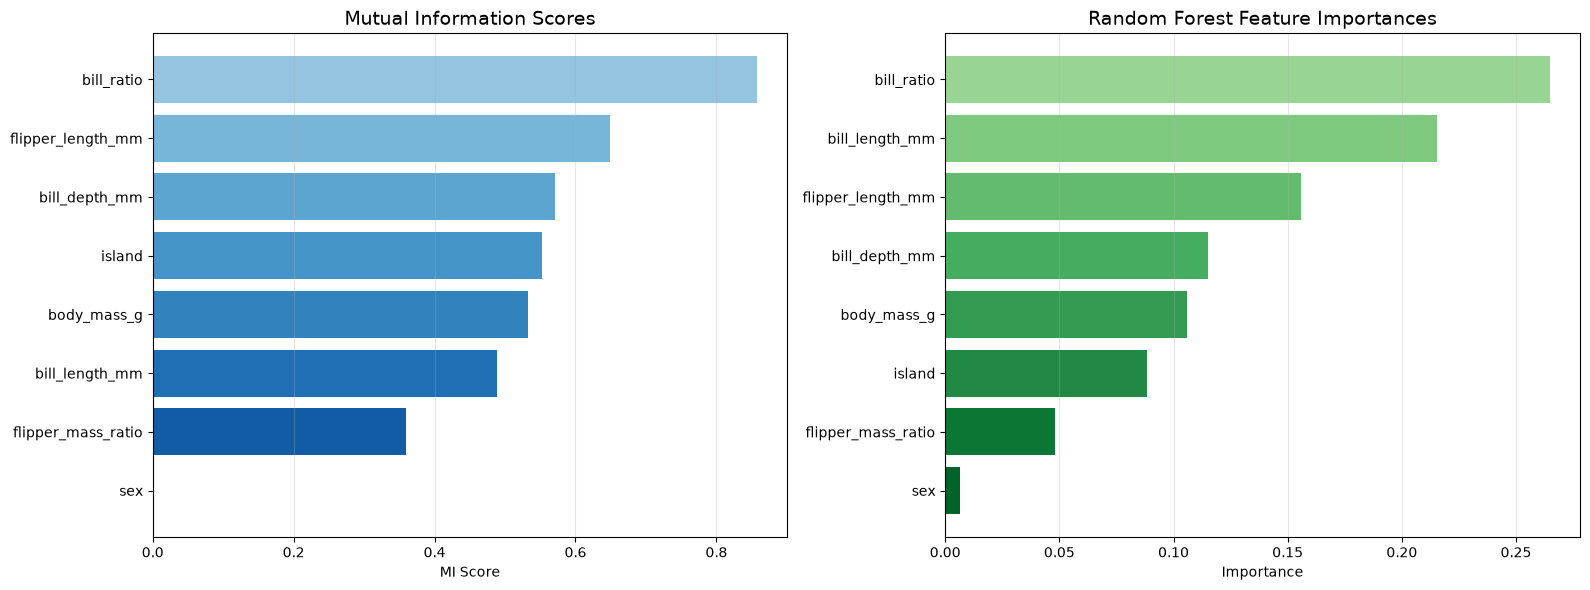

In [36]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# График 1: Mutual Information
colors_mi = plt.cm.Blues(np.linspace(0.4, 0.9, len(mi_df)))
axes[0].barh(mi_df['Feature'][::-1], mi_df['MI_Score'][::-1], color=colors_mi[::-1])
axes[0].set_title('Mutual Information Scores', fontsize=14)
axes[0].set_xlabel('MI Score')
axes[0].grid(axis='x', alpha=0.3)

# График 2: Random Forest Importances
colors_rf = plt.cm.Greens(np.linspace(0.4, 0.9, len(rf_df)))
axes[1].barh(rf_df['Feature'][::-1], rf_df['RF_Importance'][::-1], color=colors_rf[::-1])
axes[1].set_title('Random Forest Feature Importances', fontsize=14)
axes[1].set_xlabel('Importance')
axes[1].grid(axis='x', alpha=0.3)

plt.tight_layout()
plt.show()

In [37]:
# === 5. Отбор признаков и проверка качества ===

from sklearn.feature_selection import mutual_info_classif
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score

# 1. Mutual Information
mi_scores = mutual_info_classif(X_train_clean, y_train_clean, random_state=42)
mi_df = pd.DataFrame({'feature': feature_names, 'MI': mi_scores}).sort_values('MI', ascending=False)
top_mi = set(mi_df.head(5)['feature'])

# 2. Feature Importance (RF)
rf = RandomForestClassifier(n_estimators=100, random_state=42)
rf.fit(X_train_clean, y_train_clean)
imp_df = pd.DataFrame({'feature': feature_names, 'importance': rf.feature_importances_}).sort_values('importance', ascending=False)
top_imp = set(imp_df.head(5)['feature'])

# 3. Пересечение топ-5
selected_features = sorted(list(top_mi & top_imp))
print(f"Топ-5 MI:  {list(top_mi)}")
print(f"Топ-5 RF:  {list(top_imp)}")
print(f"Отобрано:  {selected_features}")

# 4. Сравнение качества
selected_indices = [feature_names.index(f) for f in selected_features]

rf_all = RandomForestClassifier(n_estimators=100, random_state=42)
rf_all.fit(X_train_clean, y_train_clean)
acc_all = accuracy_score(y_test, rf_all.predict(X_test_proc))

rf_sel = RandomForestClassifier(n_estimators=100, random_state=42)
rf_sel.fit(X_train_clean[:, selected_indices], y_train_clean)
acc_sel = accuracy_score(y_test, rf_sel.predict(X_test_proc[:, selected_indices]))

print(f"\nAccuracy (все {X_train_clean.shape[1]} признаков):    {acc_all:.4f}")
print(f"Accuracy ({len(selected_features)} отобранных):           {acc_sel:.4f}")
print(f"Δ: {acc_sel - acc_all:+.4f}")

Топ-5 MI:  ['flipper_length_mm', 'body_mass_g', 'island', 'bill_depth_mm', 'bill_ratio']
Топ-5 RF:  ['flipper_length_mm', 'bill_length_mm', 'body_mass_g', 'bill_depth_mm', 'bill_ratio']
Отобрано:  ['bill_depth_mm', 'bill_ratio', 'body_mass_g', 'flipper_length_mm']

Accuracy (все 8 признаков):    0.9565
Accuracy (4 отобранных):           0.9420
Δ: -0.0145


In [ ]:
# === Шаг 6: Итоговый пайплайн (исправленный) ===

from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import accuracy_score, classification_report
from sklearn.base import BaseEstimator, TransformerMixin

# --- Кастомный трансформер: отбор признаков по индексам ---
class FeatureSelector(BaseEstimator, TransformerMixin):
    def __init__(self, indices=None):
        self.indices = indices
    def fit(self, X, y=None):
        return self
    def transform(self, X):
        return X[:, self.indices]


final_pipeline = Pipeline([
    ('encode', preprocessor_gen),                              # кодирование
    ('impute', IterativeImputer(max_iter=20, random_state=42)),# импутация
    ('scale', StandardScaler()),                               # масштабирование
    ('select', FeatureSelector(selected_indices)),             # отбор 4 признаков
    ('model', RandomForestClassifier(random_state=42))         # модель
])

# --- Подбор гиперпараметров ---
param_grid = {
    'model__n_estimators': [100, 200],
    'model__max_depth': [5, 10, None],
    'model__min_samples_split': [2, 5]
}

grid = GridSearchCV(final_pipeline, param_grid, cv=5, scoring='accuracy', n_jobs=-1)
grid.fit(X_train, y_train)

print(f"Лучшие параметры: {grid.best_params_}")
print(f"Лучшая CV accuracy: {grid.best_score_:.4f}")

# --- Оценка на тесте ---
y_pred = grid.predict(X_test)
print(f"\nTest accuracy: {accuracy_score(y_test, y_pred):.4f}")
print("\nClassification Report:")
print(classification_report(y_test, y_pred))

Лучшие параметры: {'model__max_depth': None, 'model__min_samples_split': 5, 'model__n_estimators': 200}
Лучшая CV accuracy: 0.9345

Test accuracy: 0.9565

Classification Report:
              precision    recall  f1-score   support

      Adelie       1.00      0.93      0.97        30
   Chinstrap       0.82      1.00      0.90        14
      Gentoo       1.00      0.96      0.98        25

    accuracy                           0.96        69
   macro avg       0.94      0.96      0.95        69
weighted avg       0.96      0.96      0.96        69

